# Autoencoder-Augmented XGBoost — Binary IDS Gate
**Pipeline:** RobustScaler → Autoencoder (benign-only) → concat [features | latent_z | recon_error] → XGBoost (binary)

**Nguyên lý:**
- Autoencoder học reconstruct benign traffic → latent code + reconstruction error là tín hiệu bất thường (kể cả zero-day)
- AE chỉ đóng vai trò **feature encoder** — latent_z (16) + recon_error (1) được nối vào 78 feature gốc
- XGBoost là điểm quyết định **duy nhất**: tự học cách dùng tín hiệu AE, quyết định bằng 1 threshold trên xgb_proba (không có ngưỡng AE riêng / không OR-Fusion)

## CELL 1 — Imports & Config

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_auc_score
)
import xgboost as xgb
import joblib
import time
import os


DATA_PATH = '../binary_split_dataset_z_Infilteration/'

# Thu muc luu output - tao moi lan chay neu chua co
IMAGES_DIR = 'images'
CKPT_DIR   = 'checkpoints'
os.makedirs(IMAGES_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

SCALER_PATH = os.path.join(CKPT_DIR, 'scaler_ae.pkl')
AE_CKPT_PATH = os.path.join(CKPT_DIR, 'ae_best.pt')
XGB_PATH    = os.path.join(CKPT_DIR, 'xgb_aug_model.pkl')

DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED      = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

FEATURES = [
    'Dst Port', 'Protocol', 'Flow Duration', 'Tot Fwd Pkts',
    'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
    'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max',
    'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s',
    'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
    'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
    'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min',
    'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags',
    'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s',
    'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var',
    'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt',
    'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt',
    'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg',
    'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg',
    'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Subflow Fwd Pkts', 'Subflow Fwd Byts',
    'Subflow Bwd Pkts', 'Subflow Bwd Byts', 'Init Fwd Win Byts',
    'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Fwd Seg Size Min',
    'Active Mean', 'Active Std', 'Active Max', 'Active Min',
    'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min'
]

DTYPE_DICT = {feat: 'float32' for feat in FEATURES}
DTYPE_DICT['Label'] = 'int8'

print(f'Device : {DEVICE}')
print(f'Features: {len(FEATURES)}')

Device : cuda
Features: 78


In [5]:
# Thêm cột Label=1 vào Infilteration.csv, đồng thời lọc duplicate header rows
import pandas as pd

infilteration_path = DATA_PATH + 'Infilteration.csv'
df_inf = pd.read_csv(infilteration_path, dtype=str)  # đọc tất cả dạng string

# Lọc bỏ các dòng bị lặp header (dòng có giá trị 'Dst Port' ở cột Dst Port)
before = len(df_inf)
df_inf = df_inf[df_inf['Dst Port'] != 'Dst Port'].copy()
after = len(df_inf)
print(f'Filtered {before - after} duplicate header rows')

df_inf['Label'] = '1'
# KHONG ghi de file goc - Infilteration.csv duoc dung chung boi AE/SVDD/comparison
# notebooks, ghi de se lam hong du lieu goc dung chung. Chi xu ly trong bo nho.

print(f'Done. Shape: {df_inf.shape}')
print('Columns:', df_inf.columns.tolist()[-3:])

Filtered 1 duplicate header rows
Done. Shape: (161934, 80)
Columns: ['Idle Max', 'Idle Min', 'Label']


## CELL 2 — Load Data

In [6]:
print('Loading data...')

train_ae_df = pd.read_csv(
    DATA_PATH + 'train_isolation_benign.csv',
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT
)

train_xgb_df = pd.read_csv(
    DATA_PATH + 'train_xgboost_binary.csv',
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT
)

val_df  = pd.read_csv(DATA_PATH + 'val_binary.csv',  usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)
test_df = pd.read_csv(DATA_PATH + 'test_binary.csv', usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)

# Infilteration.csv co the chua duplicate-header rows (gia tri 'Dst Port' lap lai
# trong du lieu) -> doc dang string truoc, loc bo, roi moi ep kieu sang DTYPE_DICT.
# Khong ghi de file goc tren dia (file nay dung chung cho AE/SVDD/comparison).
test_zeroshot_df = pd.read_csv(
    DATA_PATH + 'Infilteration.csv',
    usecols=FEATURES + ['Label'],
    dtype=str
)
test_zeroshot_df = test_zeroshot_df[test_zeroshot_df['Dst Port'] != 'Dst Port'].copy()
test_zeroshot_df = test_zeroshot_df.astype(DTYPE_DICT)

print(f'AE  train (benign only) : {len(train_ae_df):,}')
print(f'XGB train (binary)      : {len(train_xgb_df):,}  | attack={train_xgb_df["Label"].sum():,}')
print(f'Val                     : {len(val_df):,}')
print(f'Test                    : {len(test_df):,}')
print(f'Zero-shot (Infilteration): {len(test_zeroshot_df):,}  | all attack={test_zeroshot_df["Label"].sum():,}')

Loading data...
AE  train (benign only) : 1,134,432
XGB train (binary)      : 1,418,040  | attack=283,608
Val                     : 303,855
Test                    : 303,900
Zero-shot (Infilteration): 161,934  | all attack=161,934


## CELL 3 — RobustScaler

In [7]:
X_ae_train = train_ae_df[FEATURES].values

X_xgb_train = train_xgb_df[FEATURES].values
y_xgb_train = train_xgb_df['Label'].values

X_val  = val_df[FEATURES].values;  y_val  = val_df['Label'].values
X_test = test_df[FEATURES].values; y_test = test_df['Label'].values

# Clean zeroshot trước khi scale: replace inf và NaN
X_test_zeroshot_raw = test_zeroshot_df[FEATURES].values.astype('float32')
X_test_zeroshot_raw = np.where(np.isfinite(X_test_zeroshot_raw), X_test_zeroshot_raw, 0.0)
y_test_zeroshot = test_zeroshot_df['Label'].values

if os.path.exists(SCALER_PATH):
    print(f'[Checkpoint] Found {SCALER_PATH} - loading, skipping scaler fit...')
    scaler = joblib.load(SCALER_PATH)
else:
    scaler = RobustScaler()
    scaler.fit(X_ae_train)
    joblib.dump(scaler, SCALER_PATH)
    print(f'RobustScaler fit on benign train - saved to {SCALER_PATH}')

X_ae_train_s      = scaler.transform(X_ae_train)
X_xgb_train_s     = scaler.transform(X_xgb_train)
X_val_s           = scaler.transform(X_val)
X_test_s          = scaler.transform(X_test)
X_test_zeroshot_s = scaler.transform(X_test_zeroshot_raw)

[Checkpoint] Found checkpoints\scaler_ae.pkl - loading, skipping scaler fit...


## CELL 4 — Autoencoder Architecture

```
Encoder: 84 → 64 → 32 → 16  (bottleneck)
Decoder: 16 → 32 → 64 → 84

Bottleneck 16 dims buộc model học compressed representation
của benign traffic. Pattern lạ (attack/zero-day) reconstruct kém
→ reconstruction error cao → FLAG
```

In [8]:
class BenignAutoencoder(nn.Module):
    """
    Autoencoder trained on benign-only traffic.
    Reconstruction error = anomaly score.
    Dùng LayerNorm thay BatchNorm để ổn định với mọi batch size.
    """
    def __init__(self, input_dim=84, bottleneck_dim=16):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(32, bottleneck_dim),
            nn.LayerNorm(bottleneck_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(32, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(64, input_dim) 
        )

    def forward(self, x):
        z    = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

    def reconstruction_error(self, x):
        """Per-sample MSE error — dùng làm anomaly score."""
        x_hat, _ = self.forward(x)
        return ((x - x_hat) ** 2).mean(dim=1)  



dummy = torch.randn(4, len(FEATURES))
model_test = BenignAutoencoder(input_dim=len(FEATURES), bottleneck_dim=16)
out, z = model_test(dummy)
print(f'Input shape    : {dummy.shape}')
print(f'Bottleneck shape: {z.shape}')
print(f'Output shape   : {out.shape}')
total_params = sum(p.numel() for p in model_test.parameters())
print(f'Total parameters: {total_params:,}')

Input shape    : torch.Size([4, 78])
Bottleneck shape: torch.Size([4, 16])
Output shape   : torch.Size([4, 78])
Total parameters: 15,806


## CELL 4b — Kiểm tra data sau scaling (chạy trước khi train)

In [9]:
print('=== Sanity check X_ae_train_s ===')
print(f'Shape  : {X_ae_train_s.shape}')
print(f'NaN    : {np.isnan(X_ae_train_s).sum()}')
print(f'Inf    : {np.isinf(X_ae_train_s).sum()}')
print(f'Max abs: {np.abs(X_ae_train_s).max():.4f}')
print(f'Mean   : {X_ae_train_s.mean():.4f}')
print(f'Std    : {X_ae_train_s.std():.4f}')

# Tìm feature nào vẫn còn scale lớn sau RobustScaler
feat_max = np.abs(X_ae_train_s).max(axis=0)
bad_feats = [(FEATURES[i], feat_max[i]) for i in np.argsort(feat_max)[::-1][:10]]
print('\nTop 10 features có |max| lớn nhất sau scaling:')
for fname, fmax in bad_feats:
    flag = ' ← cần clip' if fmax > 10 else ''
    print(f'  {fname:<30} max={fmax:.2f}{flag}')

# Clip outlier cực lớn về [-20, 20] — giảm MSE loss scale
CLIP_VAL = 20.0
X_ae_train_s  = np.clip(X_ae_train_s,  -CLIP_VAL, CLIP_VAL)
X_xgb_train_s = np.clip(X_xgb_train_s, -CLIP_VAL, CLIP_VAL)
X_val_s        = np.clip(X_val_s,       -CLIP_VAL, CLIP_VAL)
X_test_s       = np.clip(X_test_s,      -CLIP_VAL, CLIP_VAL)

print(f'\nSau clip [-{CLIP_VAL}, {CLIP_VAL}]:')
print(f'  Max abs: {np.abs(X_ae_train_s).max():.4f}')
print(f'  NaN: {np.isnan(X_ae_train_s).sum()}  Inf: {np.isinf(X_ae_train_s).sum()}')
print('Data sẵn sàng để train.')

=== Sanity check X_ae_train_s ===
Shape  : (1134432, 78)
NaN    : 0
Inf    : 0
Max abs: 606052024320.0000
Mean   : 164047.4531
Std    : 72803904.0000

Top 10 features có |max| lớn nhất sau scaling:
  Idle Max                       max=606052024320.00 ← cần clip
  Idle Mean                      max=259393421312.00 ← cần clip
  Idle Std                       max=176008085504.00 ← cần clip
  Idle Min                       max=51960000512.00 ← cần clip
  Flow IAT Std                   max=606350784.00 ← cần clip
  Flow IAT Min                   max=257909712.00 ← cần clip
  Bwd URG Flags                  max=119963752.00 ← cần clip
  Fwd URG Flags                  max=119963752.00 ← cần clip
  Fwd PSH Flags                  max=119963752.00 ← cần clip
  Active Max                     max=113170568.00 ← cần clip

Sau clip [-20.0, 20.0]:
  Max abs: 20.0000
  NaN: 0  Inf: 0
Data sẵn sàng để train.


## CELL 5 — Train Autoencoder

In [10]:
BOTTLENECK_DIM = 16    
EPOCHS         = 100
BATCH_SIZE     = 2048
LR             = 1e-2 
PATIENCE       = 7    
GRAD_CLIP      = 1.0   
val_ae_size = int(len(X_ae_train_s) * 0.1)
idx_shuffle = np.random.permutation(len(X_ae_train_s))
X_ae_val_s   = X_ae_train_s[idx_shuffle[:val_ae_size]]
X_ae_fit_s   = X_ae_train_s[idx_shuffle[val_ae_size:]]

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_ae_fit_s, dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True
)
val_ae_loader = DataLoader(
    TensorDataset(torch.tensor(X_ae_val_s, dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=False, drop_last=False
)

ae_model  = BenignAutoencoder(input_dim=len(FEATURES),
                               bottleneck_dim=BOTTLENECK_DIM).to(DEVICE)
optimizer = optim.Adam(ae_model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, verbose=True
)
criterion = nn.MSELoss()


train_losses, val_losses = [], []
best_val_loss = float('inf')
patience_counter = 0

if os.path.exists(AE_CKPT_PATH):
    print(f'[Checkpoint] Found {AE_CKPT_PATH} - loading, skipping training...')
    ae_model.load_state_dict(torch.load(AE_CKPT_PATH, map_location=DEVICE))
    print('Loaded best checkpoint.')
else:
    print(f'Training Autoencoder — {EPOCHS} epochs, bottleneck={BOTTLENECK_DIM}')
    print(f'Train: {len(X_ae_fit_s):,}  |  Val: {len(X_ae_val_s):,}')
    print('-' * 55)

    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        # Train
        ae_model.train()
        epoch_loss = 0.0
        for (xb,) in train_loader:
            xb = xb.to(DEVICE)
            x_hat, _ = ae_model(xb)
            loss = criterion(x_hat, xb)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(ae_model.parameters(), GRAD_CLIP)  
            optimizer.step()
            epoch_loss += loss.item()
        avg_train = epoch_loss / len(train_loader)

        if np.isnan(avg_train) or avg_train > 1e10:
            print(f'  ⚠ Loss nổ tại epoch {epoch} ({avg_train:.2e}) — dừng. Thử giảm LR thêm.')
            break

        # Validation
        ae_model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for (xb,) in val_ae_loader:
                xb = xb.to(DEVICE)
                x_hat, _ = ae_model(xb)
                val_loss += criterion(x_hat, xb).item()
        avg_val = val_loss / len(val_ae_loader)

        train_losses.append(avg_train)
        val_losses.append(avg_val)
        scheduler.step(avg_val)

        if epoch % 5 == 0 or epoch == 1:
            print(f'  Epoch {epoch:3d}/{EPOCHS}  train={avg_train:.6f}  val={avg_val:.6f}')

        # Early stopping
        if avg_val < best_val_loss:
            best_val_loss = avg_val
            torch.save(ae_model.state_dict(), AE_CKPT_PATH)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f'  Early stopping tại epoch {epoch}')
                break

    print(f'\nTraining time: {time.time()-t0:.1f}s')
    print(f'Best val loss: {best_val_loss:.6f}')

    # Load best checkpoint
    ae_model.load_state_dict(torch.load(AE_CKPT_PATH, map_location=DEVICE))
    print('Loaded best checkpoint.')


[Checkpoint] Found checkpoints\ae_best.pt - loading, skipping training...
Loaded best checkpoint.


## CELL 6 — Plot Training Curve

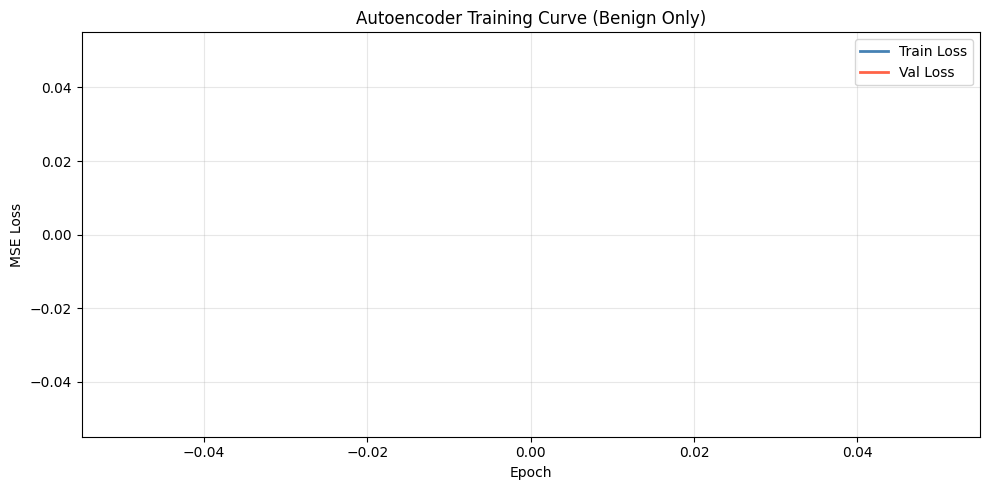

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='Train Loss', color='steelblue', linewidth=2)
ax.plot(val_losses,   label='Val Loss',   color='tomato',    linewidth=2)
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.set_title('Autoencoder Training Curve (Benign Only)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'ae_training_curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## CELL 7 — Tính Reconstruction Error & Visualize Distribution

Computing reconstruction errors + latent features...
Latent shape (train): (1418040, 16)
Train — benign error mean : 0.724526
Val   — benign error mean : 0.732087
Val   — attack error mean : 3.361513
Test  — benign error mean : 0.728630
Test  — attack error mean : 3.386557


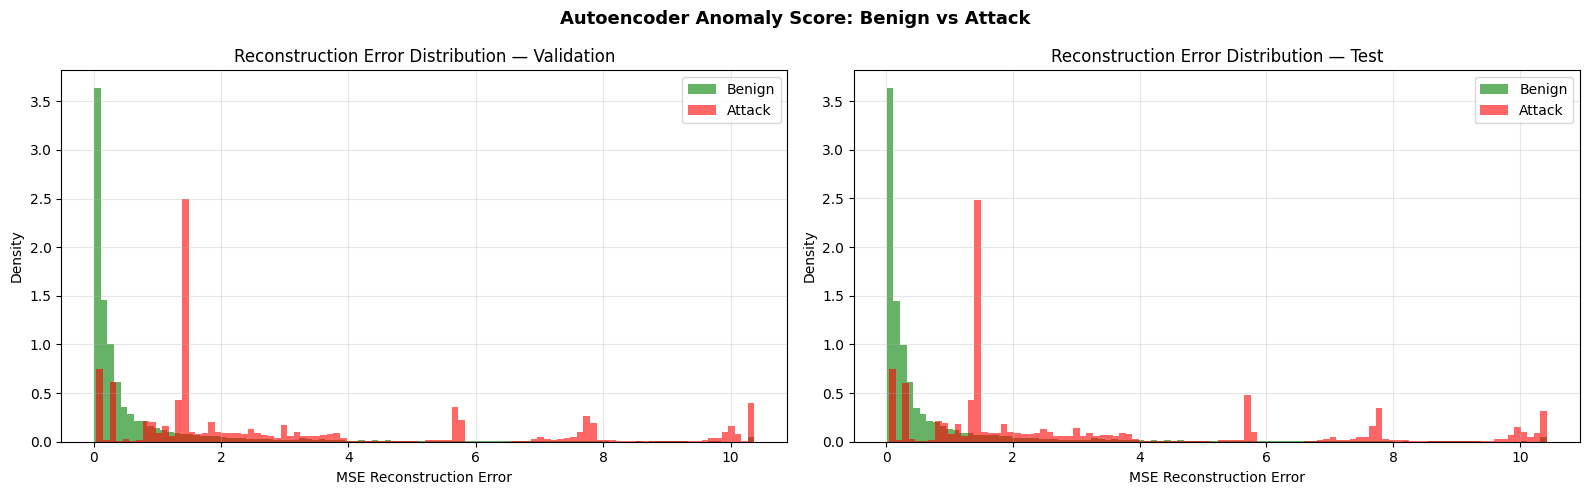

In [12]:
def get_recon_errors(model, X_np, batch_size=4096, device='cpu'):
    """Tính per-sample reconstruction error cho toàn bộ dataset."""
    model.eval()
    loader = DataLoader(
        TensorDataset(torch.tensor(X_np, dtype=torch.float32)),
        batch_size=batch_size, shuffle=False, drop_last=False
    )
    errors = []
    with torch.no_grad():
        for (xb,) in loader:
            xb = xb.to(device)
            err = ae_model.reconstruction_error(xb)
            errors.append(err.cpu().numpy())
    return np.concatenate(errors)


def get_latent(model, X_np, batch_size=4096, device='cpu'):
    """Trích xuất bottleneck embedding z cho toàn bộ dataset."""
    model.eval()
    loader = DataLoader(
        TensorDataset(torch.tensor(X_np, dtype=torch.float32)),
        batch_size=batch_size, shuffle=False, drop_last=False
    )
    latents = []
    with torch.no_grad():
        for (xb,) in loader:
            xb = xb.to(device)
            _, z = ae_model(xb)
            latents.append(z.cpu().numpy())
    return np.concatenate(latents)  


print('Computing reconstruction errors + latent features...')
ae_errors_train = get_recon_errors(ae_model, X_xgb_train_s, device=DEVICE)
ae_errors_val   = get_recon_errors(ae_model, X_val_s,       device=DEVICE)
ae_errors_test  = get_recon_errors(ae_model, X_test_s,      device=DEVICE)

ae_latent_train = get_latent(ae_model, X_xgb_train_s, device=DEVICE)
ae_latent_val   = get_latent(ae_model, X_val_s,       device=DEVICE)
ae_latent_test  = get_latent(ae_model, X_test_s,      device=DEVICE)

print(f'Latent shape (train): {ae_latent_train.shape}')
print(f'Train — benign error mean : {ae_errors_train[y_xgb_train==0].mean():.6f}')
print(f'Val   — benign error mean : {ae_errors_val[y_val==0].mean():.6f}')
print(f'Val   — attack error mean : {ae_errors_val[y_val==1].mean():.6f}')
print(f'Test  — benign error mean : {ae_errors_test[y_test==0].mean():.6f}')
print(f'Test  — attack error mean : {ae_errors_test[y_test==1].mean():.6f}')


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, split, errors, labels in [
    (axes[0], 'Validation', ae_errors_val,  y_val),
    (axes[1], 'Test',       ae_errors_test, y_test)
]:

    clip_val = np.percentile(errors, 99)
    errors_clipped = np.clip(errors, 0, clip_val)

    ax.hist(errors_clipped[labels==0], bins=100, alpha=0.6,
            color='green', label='Benign', density=True)
    ax.hist(errors_clipped[labels==1], bins=100, alpha=0.6,
            color='red',   label='Attack', density=True)
    ax.set_title(f'Reconstruction Error Distribution — {split}')
    ax.set_xlabel('MSE Reconstruction Error')
    ax.set_ylabel('Density')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle('Autoencoder Anomaly Score: Benign vs Attack', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'ae_error_dist.png'), dpi=150, bbox_inches='tight')
plt.show()

## CELL 8 — Autoencoder Standalone Evaluation

In [13]:
def evaluate(name, y_true, y_pred, y_score=None):
    print(f"\n{'='*55}")
    print(f'  {name}')
    print(f"{'='*55}")
    print(classification_report(y_true, y_pred,
                                target_names=['Benign','Attack'], digits=4))
    cm = confusion_matrix(y_true, y_pred)
    cm_flat = cm.ravel()
    if len(cm_flat) == 4:
        tn, fp, fn, tp = cm_flat
    else:
        tn, fp, fn, tp = (cm[0,0], 0, 0, 0) if y_pred.sum()==0 else (0, 0, 0, cm[0,0])
    print(f'  TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}')
    rec = tp/(tp+fn) if (tp+fn)>0 else 0.0
    pre = tp/(tp+fp) if (tp+fp)>0 else 0.0
    print(f'  Recall (Attack) = {rec:.4f}   ← zero-shot proxy')
    if y_score is not None:
        print(f'  AUC-ROC = {roc_auc_score(y_true, y_score):.4f}')
    return {'f1': f1_score(y_true, y_pred, zero_division=0),
            'recall': rec, 'precision': pre,
            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp}



FPR_BUDGET = 0.05  
ae_threshold = np.percentile(ae_errors_val[y_val == 0], (1 - FPR_BUDGET) * 100)
print(f'AE threshold (FPR budget {FPR_BUDGET*100:.0f}%): {ae_threshold:.6f}')

# Inference timing
t0 = time.time()
ae_pred_val  = (ae_errors_val  > ae_threshold).astype(int)
ae_pred_test = (ae_errors_test > ae_threshold).astype(int)
print(f'AE inference time: {(time.time()-t0)/len(X_val_s)*1000:.4f} ms/sample')

res_ae_val  = evaluate('Autoencoder — Validation', y_val,  ae_pred_val,  ae_errors_val)
res_ae_test = evaluate('Autoencoder — Test',       y_test, ae_pred_test, ae_errors_test)

AE threshold (FPR budget 5%): 3.378922
AE inference time: 0.0000 ms/sample

  Autoencoder — Validation
              precision    recall  f1-score   support

      Benign     0.8437    0.9500    0.8937    243084
      Attack     0.5967    0.2959    0.3956     60771

    accuracy                         0.8192    303855
   macro avg     0.7202    0.6229    0.6446    303855
weighted avg     0.7943    0.8192    0.7941    303855

  TN=230,929  FP=12,155  FN=42,790  TP=17,981
  Recall (Attack) = 0.2959   ← zero-shot proxy
  AUC-ROC = 0.8488

  Autoencoder — Test
              precision    recall  f1-score   support

      Benign     0.8443    0.9500    0.8940    243120
      Attack     0.5991    0.2991    0.3990     60780

    accuracy                         0.8198    303900
   macro avg     0.7217    0.6245    0.6465    303900
weighted avg     0.7952    0.8198    0.7950    303900

  TN=230,956  FP=12,164  FN=42,599  TP=18,181
  Recall (Attack) = 0.2991   ← zero-shot proxy
  AUC-ROC = 0.84

## CELL 9 — Train XGBoost

## CELL 9b — Build AE-Augmented Features cho XGBoost

```
Augmented input = [original(84) | latent_z(16) | recon_error(1)]
                                                    = 101 dims

latent_z     : compressed representation — feature lạ so với
               benign sẽ có z khác biệt, XGBoost học được
recon_error  : anomaly score trực tiếp — zero-day sẽ có
               giá trị cao, XGBoost tự học cách dùng signal này
```

In [14]:
LATENT_FEATURES = [f'ae_latent_{i}' for i in range(BOTTLENECK_DIM)]
AUGMENTED_FEATURES = FEATURES + LATENT_FEATURES + ['ae_recon_error']


X_aug_train = np.concatenate([
    X_xgb_train_s,
    ae_latent_train,
    ae_errors_train.reshape(-1, 1)
], axis=1)

X_aug_val = np.concatenate([
    X_val_s,
    ae_latent_val,
    ae_errors_val.reshape(-1, 1)
], axis=1)

X_aug_test = np.concatenate([
    X_test_s,
    ae_latent_test,
    ae_errors_test.reshape(-1, 1)
], axis=1)

print(f'Original features : {X_xgb_train_s.shape[1]}')
print(f'Latent features   : {ae_latent_train.shape[1]}')
print(f'Recon error       : 1')
print(f'Augmented total   : {X_aug_train.shape[1]}  ← XGBoost input')
print(f'\nX_aug_train shape : {X_aug_train.shape}')
print(f'NaN check         : {np.isnan(X_aug_train).sum()}')

Original features : 78
Latent features   : 16
Recon error       : 1
Augmented total   : 95  ← XGBoost input

X_aug_train shape : (1418040, 95)
NaN check         : 0


In [15]:
scale_pos = int((y_xgb_train == 0).sum()) / int((y_xgb_train == 1).sum())
print(f'scale_pos_weight = {scale_pos:.2f}')

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    eval_metric='logloss',
    random_state=SEED,
    n_jobs=-1,
    tree_method='hist',
    device='cuda' if torch.cuda.is_available() else 'cpu',
    early_stopping_rounds=20
)

if os.path.exists(XGB_PATH):
    print(f'[Checkpoint] Found {XGB_PATH} - loading, skipping training...')
    xgb_model = joblib.load(XGB_PATH)
else:
    print('Training AE-Augmented XGBoost (101 features)...')
    t0 = time.time()
    xgb_model.fit(
        X_aug_train, y_xgb_train,
        eval_set=[(X_aug_val, y_val)],
        verbose=50
    )
    print(f'Training time: {time.time()-t0:.1f}s')
    joblib.dump(xgb_model, XGB_PATH)


xgb_proba_val  = xgb_model.predict_proba(X_aug_val)[:, 1]
xgb_proba_test = xgb_model.predict_proba(X_aug_test)[:, 1]
xgb_pred_val   = (xgb_proba_val  >= 0.5).astype(int)
xgb_pred_test  = (xgb_proba_test >= 0.5).astype(int)


res_xgb_test = evaluate('AE-Aug XGBoost — Test',       y_test, xgb_pred_test, xgb_proba_test)

scale_pos_weight = 4.00
[Checkpoint] Found checkpoints\xgb_aug_model.pkl - loading, skipping training...

  AE-Aug XGBoost — Test
              precision    recall  f1-score   support

      Benign     0.9996    0.9974    0.9985    243120
      Attack     0.9896    0.9984    0.9940     60780

    accuracy                         0.9976    303900
   macro avg     0.9946    0.9979    0.9962    303900
weighted avg     0.9976    0.9976    0.9976    303900

  TN=242,480  FP=640  FN=96  TP=60,684
  Recall (Attack) = 0.9984   ← zero-shot proxy
  AUC-ROC = 1.0000


## CELL 10 — SHAP Feature Importance

Computing SHAP values on augmented features (5000 samples)...


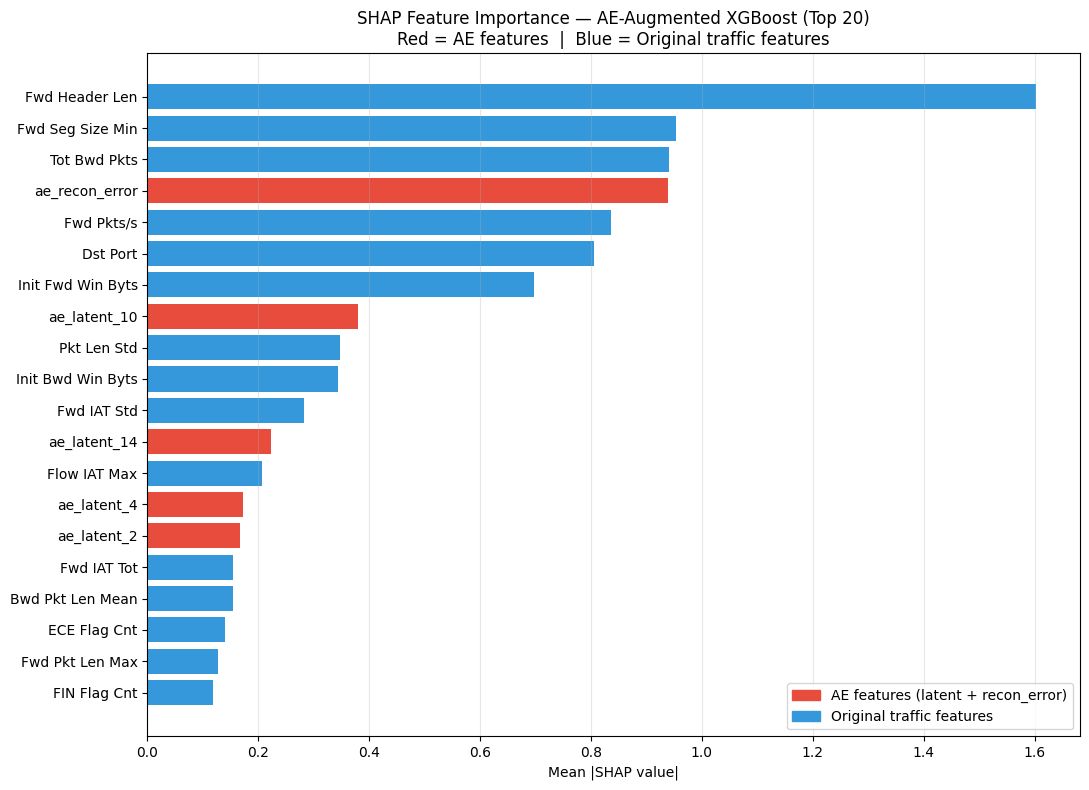


Top 20 features by SHAP:
   1. Fwd Header Len                   1.601961
   2. Fwd Seg Size Min                 0.953158
   3. Tot Bwd Pkts                     0.941144
   4. ae_recon_error                   0.938828 ◀ AE feature
   5. Fwd Pkts/s                       0.835778
   6. Dst Port                         0.805781
   7. Init Fwd Win Byts                0.698134
   8. ae_latent_10                     0.379827 ◀ AE feature
   9. Pkt Len Std                      0.347744
  10. Init Bwd Win Byts                0.343407
  11. Fwd IAT Std                      0.282650
  12. ae_latent_14                     0.223540 ◀ AE feature
  13. Flow IAT Max                     0.207254
  14. ae_latent_4                      0.171986 ◀ AE feature
  15. ae_latent_2                      0.167849 ◀ AE feature
  16. Fwd IAT Tot                      0.155115
  17. Bwd Pkt Len Mean                 0.155113
  18. ECE Flag Cnt                     0.140648
  19. Fwd Pkt Len Max                  0.1271

In [16]:
import shap

print('Computing SHAP values on augmented features (5000 samples)...')
shap_idx   = np.random.choice(len(X_aug_val), min(5000, len(X_aug_val)), replace=False)
explainer  = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_aug_val[shap_idx])

mean_abs_shap  = np.abs(shap_values).mean(axis=0)
top20_idx      = np.argsort(mean_abs_shap)[::-1][:20]
top20_features = [AUGMENTED_FEATURES[i] for i in top20_idx]


colors = ['#e74c3c' if 'ae_' in f else '#3498db' for f in top20_features]

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(range(len(top20_features)),
               mean_abs_shap[top20_idx][::-1],
               color=colors[::-1])
ax.set_yticks(range(len(top20_features)))
ax.set_yticklabels(top20_features[::-1], fontsize=10)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('SHAP Feature Importance — AE-Augmented XGBoost (Top 20)\n'
             'Red = AE features  |  Blue = Original traffic features')

# Legend
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#e74c3c', label='AE features (latent + recon_error)'),
    Patch(color='#3498db', label='Original traffic features')
], loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'shap_augmented.png'), dpi=150, bbox_inches='tight')
plt.show()


print('\nTop 20 features by SHAP:')
for i, (f, v) in enumerate(zip(top20_features, mean_abs_shap[top20_idx])):
    tag = ' ◀ AE feature' if 'ae_' in f else ''
    print(f'  {i+1:2d}. {f:<32} {v:.6f}{tag}')


ae_feat_idx  = [i for i, f in enumerate(AUGMENTED_FEATURES) if 'ae_' in f]
org_feat_idx = [i for i, f in enumerate(AUGMENTED_FEATURES) if 'ae_' not in f]
ae_contrib   = mean_abs_shap[ae_feat_idx].sum()
org_contrib  = mean_abs_shap[org_feat_idx].sum()
total        = ae_contrib + org_contrib
print(f'\nAE features contribution  : {ae_contrib/total*100:.1f}%')
print(f'Original features contribution: {org_contrib/total*100:.1f}%')

In [17]:
# --- CELL 11: Kiểm thử Zero-shot dataset bằng XGBoost ---
import time

print("1. Đang chuẩn bị dữ liệu zeroshot...")
# X_test_zeroshot_s đã được scale + clean ở Cell 3
X_zeroshot_s = np.clip(X_test_zeroshot_s, -CLIP_VAL, CLIP_VAL)

print("2. Đang trích xuất augmented features (Latent + Error) từ AE...")
e_zero = get_recon_errors(ae_model, X_zeroshot_s, device=DEVICE)
z_zero = get_latent(ae_model, X_zeroshot_s, device=DEVICE)

X_aug_zero = np.concatenate([X_zeroshot_s, z_zero, e_zero.reshape(-1, 1)], axis=1)

print("3. Predict bằng mô hình XGBoost...")
t0 = time.time()
xgb_proba_zero = xgb_model.predict_proba(X_aug_zero)[:, 1]
xgb_pred_zero = (xgb_proba_zero >= 0.5).astype(int)
print(f"Thời gian inference: {time.time()-t0:.2f}s\n")

print("4. Đánh giá kết quả (Tập Zero-shot toàn bộ là Attack)")
y_zero = np.array(y_test_zeroshot)
total_samples = len(y_zero)
correct_preds = (xgb_pred_zero == 1).sum()
missed_preds = total_samples - correct_preds
recall_zero = correct_preds / total_samples

print(f"Tổng số mẫu Attack (Zero-shot): {total_samples:,}")
print(f"XGBoost phát hiện đúng (True Positives): {correct_preds:,}")
print(f"XGBoost bỏ sót (False Negatives): {missed_preds:,}")
print(f"Recall (Tỉ lệ phát hiện - Detection Rate): {recall_zero * 100:.2f}%")

1. Đang chuẩn bị dữ liệu zeroshot...
2. Đang trích xuất augmented features (Latent + Error) từ AE...
3. Predict bằng mô hình XGBoost...
Thời gian inference: 0.26s

4. Đánh giá kết quả (Tập Zero-shot toàn bộ là Attack)
Tổng số mẫu Attack (Zero-shot): 161,934
XGBoost phát hiện đúng (True Positives): 1,260
XGBoost bỏ sót (False Negatives): 160,674
Recall (Tỉ lệ phát hiện - Detection Rate): 0.78%


In [18]:
print('\n' + '='*65)
print('  ABLATION STUDY SUMMARY — Test Set')
print('='*65)
print(f'{"Method":<32} {"F1":>8} {"Recall":>8} {"Precision":>10}')
print('-'*65)
for name, res in [
    ('① AE only (baseline)',        res_ae_test),
    ('② AE-Aug XGBoost (proposed)', res_xgb_test),
]:
    print(f'{name:<32} {res["f1"]:>8.4f} {res["recall"]:>8.4f} {res["precision"]:>10.4f}')
print('='*65)
print('Note: ② dùng 95 features (78 original + 16 latent + 1 recon_error).')
print('      AE chỉ đóng vai trò feature encoder — XGBoost là điểm quyết định')
print('      duy nhất (threshold đơn trên xgb_proba), không có ngưỡng AE riêng.')


  ABLATION STUDY SUMMARY — Test Set
Method                                 F1   Recall  Precision
-----------------------------------------------------------------
① AE only (baseline)               0.3990   0.2991     0.5991
② AE-Aug XGBoost (proposed)        0.9940   0.9984     0.9896
Note: ② dùng 95 features (78 original + 16 latent + 1 recon_error).
      AE chỉ đóng vai trò feature encoder — XGBoost là điểm quyết định
      duy nhất (threshold đơn trên xgb_proba), không có ngưỡng AE riêng.


## CELL 13 — Confusion Matrices

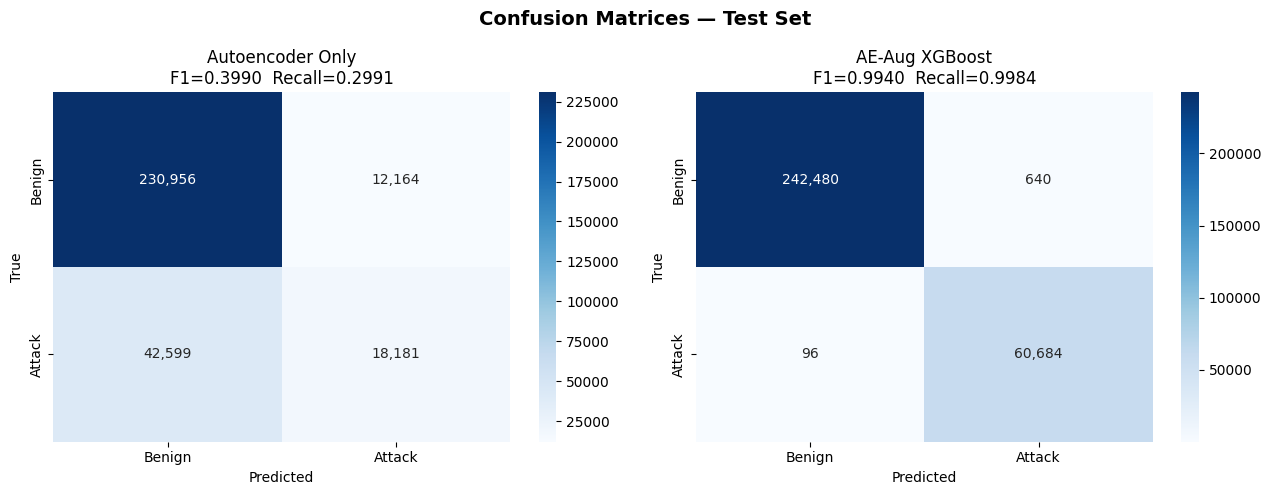

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, [
    ('Autoencoder Only', ae_pred_test),
    ('AE-Aug XGBoost',   xgb_pred_test),
]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
                xticklabels=['Benign','Attack'],
                yticklabels=['Benign','Attack'])
    ax.set_title(f'{name}\nF1={f1_score(y_test,pred,zero_division=0):.4f}  '
                 f'Recall={recall_score(y_test,pred,zero_division=0):.4f}')
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrices — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'confusion_matrices_ae.png'), dpi=150, bbox_inches='tight')
plt.show()

## CELL 14 — Inference Speed Benchmark

In [20]:
BATCH_SIZE_BENCH = 1000  # Giả lập 1000 flows sau 10s TShark
X_bench = X_test_s[:BATCH_SIZE_BENCH]

# ── Augment X_bench giống pipeline train (78 → 95 features) ──────
ae_errors_bench = get_recon_errors(ae_model, X_bench, device=DEVICE)
ae_latent_bench = get_latent(ae_model, X_bench, device=DEVICE)
X_bench_aug = np.concatenate([
    X_bench,
    ae_latent_bench,
    ae_errors_bench.reshape(-1, 1)
], axis=1)

# Warm-up
_ = get_recon_errors(ae_model, X_bench, device=DEVICE)
_ = xgb_model.predict_proba(X_bench_aug)

N_RUNS = 20
ae_times, xgb_times, total_times = [], [], []

for _ in range(N_RUNS):
    t0 = time.time(); get_recon_errors(ae_model, X_bench, device=DEVICE); ae_times.append(time.time()-t0)
    t0 = time.time(); xgb_model.predict_proba(X_bench_aug); xgb_times.append(time.time()-t0)
    t0 = time.time()
    e = get_recon_errors(ae_model, X_bench, device=DEVICE)
    z = get_latent(ae_model, X_bench, device=DEVICE)
    X_run_aug = np.concatenate([X_bench, z, e.reshape(-1, 1)], axis=1)
    p = xgb_model.predict_proba(X_run_aug)[:, 1]
    _ = (p > 0.7).astype(int)  # single XGBoost threshold — no separate AE branch
    total_times.append(time.time()-t0)

print(f'Batch size: {BATCH_SIZE_BENCH} flows')
print(f'{"Component":<22} {"Mean(ms)":>10} {"Std(ms)":>10} {"Max(ms)":>10}')
print('-'*55)
for name, times in [
    ('Autoencoder', ae_times),
    ('XGBoost',     xgb_times),
    ('Total Pipeline', total_times)
]:
    t_ms = np.array(times) * 1000
    print(f'{name:<22} {t_ms.mean():>10.2f} {t_ms.std():>10.2f} {t_ms.max():>10.2f}')

mean_total_ms = np.mean(total_times) * 1000
print(f'\n→ TShark cycle  = 10,000ms')
print(f'→ Pipeline latency = {mean_total_ms:.1f}ms')
print(f'→ Headroom       = {10000 - mean_total_ms:.0f}ms  (cho SHAP + RAG + VLM)')

Batch size: 1000 flows
Component                Mean(ms)    Std(ms)    Max(ms)
-------------------------------------------------------
Autoencoder                  7.55       0.69       9.71
XGBoost                      4.87       0.94       7.71
Total Pipeline              19.75       1.25      22.03

→ TShark cycle  = 10,000ms
→ Pipeline latency = 19.8ms
→ Headroom       = 9980ms  (cho SHAP + RAG + VLM)


## CELL 15 — Phân tích lỗi: Những attack nào AE bỏ sót?
> Quan trọng để hiểu điểm yếu của AE và justify vai trò của XGBoost trong fusion

AE False Negatives (bỏ sót): 42,599
AE True Positives  (detect) : 18,181

Error của FN (attack bị bỏ sót):
  Mean=1.341439  Max=3.378404
Error của TP (attack được detect):
  Mean=8.178371  Max=57.472549

Trong 42,599 attack AE bỏ sót:
  XGBoost bắt được : 42,537  (99.9%)
  Cả 2 đều bỏ sót : 62


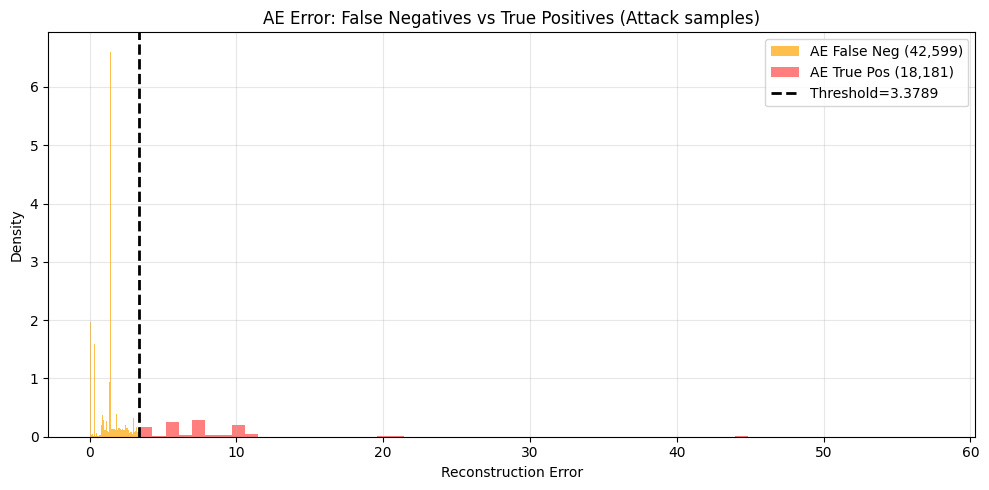

In [21]:
# Tìm False Negative của AE (attack bị classify là benign)
ae_fn_mask = (ae_pred_test == 0) & (y_test == 1)   # AE bỏ sót
ae_tp_mask = (ae_pred_test == 1) & (y_test == 1)   # AE detect đúng

print(f'AE False Negatives (bỏ sót): {ae_fn_mask.sum():,}')
print(f'AE True Positives  (detect) : {ae_tp_mask.sum():,}')

# Reconstruction error của FN vs TP
fn_errors = ae_errors_test[ae_fn_mask]
tp_errors = ae_errors_test[ae_tp_mask]

print(f'\nError của FN (attack bị bỏ sót):')
print(f'  Mean={fn_errors.mean():.6f}  Max={fn_errors.max():.6f}')
print(f'Error của TP (attack được detect):')
print(f'  Mean={tp_errors.mean():.6f}  Max={tp_errors.max():.6f}')

# XGBoost có bắt được các FN của AE không?
xgb_catches_fn = (xgb_pred_test[ae_fn_mask] == 1).sum()
print(f'\nTrong {ae_fn_mask.sum():,} attack AE bỏ sót:')
print(f'  XGBoost bắt được : {xgb_catches_fn:,}  ({xgb_catches_fn/ae_fn_mask.sum()*100:.1f}%)')
print(f'  Cả 2 đều bỏ sót : {ae_fn_mask.sum()-xgb_catches_fn:,}')

# Visualize
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(fn_errors, bins=60, alpha=0.7, color='orange', label=f'AE False Neg ({ae_fn_mask.sum():,})', density=True)
ax.hist(tp_errors, bins=60, alpha=0.5, color='red',    label=f'AE True Pos ({ae_tp_mask.sum():,})',  density=True)
ax.axvline(ae_threshold, color='black', linestyle='--', linewidth=2, label=f'Threshold={ae_threshold:.4f}')
ax.set_xlabel('Reconstruction Error'); ax.set_ylabel('Density')
ax.set_title('AE Error: False Negatives vs True Positives (Attack samples)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'ae_fn_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()